# Comparación temporal de métodos de tratamiento de faltantes

Comparamos imputación numérica por mediana, mediana con indicadores binarios y manejo nativo de `NaN` por `HistGradientBoostingClassifier`. Se mantienen las particiones temporales y los hiperparámetros ya seleccionados.

## 1. Diseño y límites

Se ejecutan seis comparaciones: las 26 variables fijadas con datos hasta 2012 y la selección de variables calculada dentro de cada corte; para cada conjunto se prueban (A) mediana, (B) mediana más indicadores numéricos y (C) NaN numéricos nativos.

Los cortes son entrenamiento hasta 2012 → validación 2013, hasta 2013 → 2014, hasta 2014 → 2015 y hasta 2015 → 2016. No se usan datos de 2017 en adelante. En cada corte, selección, mediana, indicadores, escalado y One-Hot se ajustan con entrenamiento solamente. La opción de 26 variables es fija y procede del primer entrenamiento; la selección temporal puede cambiar la cantidad de columnas entre cortes.

En el método C, las variables numéricas pasan por `StandardScaler` para mantener el mismo tratamiento numérico, pero no pasan por imputador. Se comprobará explícitamente que sus NaN lleguen intactos al clasificador. `HistGradientBoostingClassifier` puede manejar NaN numéricos nativamente. En los tres métodos, faltantes categóricos se completan con «Sin información» y luego se codifican con One-Hot.

In [1]:
from pathlib import Path
import sys, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.config import localizar_datos, MAPA_OBJETIVO, SEMILLA
from src.modelado import TIPOS_AUDITADOS
from src import features as ft

ANIOS_VALIDACION = [2013, 2014, 2015, 2016]
UMBRAL_FALTANTES = 10
ruta_datos = localizar_datos()
columnas_fuente = pd.read_csv(ruta_datos, nrows=0).columns.tolist()
candidatas = ft.seleccionar_predictoras(
    pd.DataFrame(columns=columnas_fuente), [], incluir_precio_lc=False
)
columnas_lectura = candidatas + ["loan_status", "issue_d"]
dtypes = {
    col: ("string" if TIPOS_AUDITADOS[col] in ["category", "string"] else TIPOS_AUDITADOS[col])
    for col in columnas_lectura
}
print(f"Candidatas antes del filtro: {len(candidatas)}")
print("Leyendo por bloques; se conservan solo préstamos elegibles con issue_d hasta 2016...")
partes=[]
filas_fuente=0
inicio=time.perf_counter()
with pd.read_csv(ruta_datos, usecols=columnas_lectura, dtype=dtypes,
                 chunksize=100_000, skipinitialspace=True, low_memory=False) as lector:
    for numero,bloque in enumerate(lector, start=1):
        filas_fuente += len(bloque)
        fecha = pd.to_datetime(bloque["issue_d"], format="%b-%Y", errors="coerce")
        conservar = fecha.notna() & (fecha.dt.year <= 2016)
        bloque = bloque.loc[conservar].copy()
        bloque["issue_d"] = fecha.loc[conservar]
        bloque = bloque.loc[bloque["loan_status"].isin(MAPA_OBJETIVO)].copy()
        if bloque.empty:
            continue
        for col in ["earliest_cr_line", "sec_app_earliest_cr_line"]:
            if col in bloque:
                original = bloque[col].notna()
                fecha_col = pd.to_datetime(bloque[col], format="%b-%Y", errors="coerce")
                if (original & fecha_col.isna()).any():
                    raise ValueError(f"Fecha no reconocida en {col}")
                bloque[col] = fecha_col
        if "term" in bloque:
            bloque["term"] = pd.to_numeric(
                bloque["term"].astype("string").str.strip().str.replace(" months", "", regex=False),
                errors="raise"
            ).astype("float64")
        bloque["anio"] = bloque["issue_d"].dt.year.astype("int16")
        bloque["default"] = bloque["loan_status"].map(MAPA_OBJETIVO).astype("int8")
        bloque["fecha_prestamo"] = bloque["issue_d"]
        partes.append(bloque)
        if numero % 10 == 0:
            print(f"  Bloques recorridos: {numero}; filas fuente leídas: {filas_fuente:,}",flush=True)
datos = pd.concat(partes,ignore_index=True)
del partes
datos = datos.loc[datos["anio"] <= 2016].copy()
assert datos["anio"].max() <= 2016
print(f"Datos de modelado: {len(datos):,} préstamos; años {datos.anio.min()}–{datos.anio.max()}; carga {time.perf_counter()-inicio:.1f} s")

# Lista fija de 26: cobertura menor a 10% medida solo hasta el primer corte de entrenamiento.
mask_2012 = datos["anio"] <= 2012
faltantes_2012 = datos.loc[mask_2012,candidatas].isna().mean()*100
variables_26 = faltantes_2012[faltantes_2012 < UMBRAL_FALTANTES].index.tolist()
if len(variables_26) != 26:
    raise ValueError(f"Se esperaban 26 variables fijas, se obtuvieron {len(variables_26)}")
print(f"Variables fijas: {len(variables_26)}; candidatas para selección temporal: {len(candidatas)}")

# Deriva antigüedad del historial a la fecha de otorgamiento; no estima parámetros.
def preparar_X(tabla, fecha_otorgamiento):
    X=tabla.copy()
    for col in ["earliest_cr_line","sec_app_earliest_cr_line"]:
        if col in X:
            fecha_inicio=X[col]
            nombre="meses_desde_"+col
            X[nombre]=((fecha_otorgamiento.dt.year-fecha_inicio.dt.year)*12+
                       (fecha_otorgamiento.dt.month-fecha_inicio.dt.month)).astype("float64")
            X=X.drop(columns=col)
    for col in X.columns:
        if pd.api.types.is_numeric_dtype(X[col]):
            X[col]=pd.to_numeric(X[col],errors="coerce").astype("float64").replace([np.inf,-np.inf],np.nan)
        else:
            X[col]=X[col].astype(object).where(X[col].notna(),np.nan)
    return X


Candidatas antes del filtro: 95
Leyendo por bloques; se conservan solo préstamos elegibles con issue_d hasta 2016...


  Bloques recorridos: 10; filas fuente leídas: 1,000,000


  Bloques recorridos: 20; filas fuente leídas: 2,000,000


Datos de modelado: 1,119,699 préstamos; años 2007–2016; carga 86.1 s
Variables fijas: 26; candidatas para selección temporal: 95


## 2. Preprocesamiento y control de NaN nativo

Los indicadores se calculan a partir de los valores originales antes de imputar. Para el método C se omite el imputador numérico: el escalador solo aprende centro y escala con valores observados y mantiene los NaN. La comprobación en la función confirma que la matriz transformada conserva el mismo número de NaN numéricos antes del ajuste del modelo.

In [2]:
HIPERPARAMETROS = {
    "learning_rate": 0.08118441500491742,
    "max_iter": 182,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 46,
    "l2_regularization": 0.32877474139911184,
    "early_stopping": False,
    "random_state": SEMILLA,
}

def ajustar_y_evaluar(anio_validacion, variables, metodo, nombre_experimento):
    anio_final_train=anio_validacion-1
    mask_train=datos.anio<=anio_final_train
    mask_valid=datos.anio==anio_validacion
    X_train=preparar_X(datos.loc[mask_train,variables],datos.loc[mask_train,"fecha_prestamo"])
    X_valid=preparar_X(datos.loc[mask_valid,variables],datos.loc[mask_valid,"fecha_prestamo"])
    y_train=datos.loc[mask_train,"default"].to_numpy(dtype="int8")
    y_valid=datos.loc[mask_valid,"default"].to_numpy(dtype="int8")
    numericas=[col for col in X_train if pd.api.types.is_numeric_dtype(X_train[col])]
    categoricas=[col for col in X_train if col not in numericas]
    indicadores=[]

    if metodo=="mediana_indicadores":
        # Indicadores de entrenamiento y validación se crean antes de imputar,
        # usando solo las columnas que tienen faltantes en el entrenamiento.
        for col in numericas:
            if X_train[col].isna().any():
                nombre=f"{col}__faltante"
                X_train[nombre]=X_train[col].isna().astype("int8")
                X_valid[nombre]=X_valid[col].isna().astype("int8")
                indicadores.append(nombre)

    transformadores=[]
    if numericas:
        if metodo=="nan_nativo":
            pipeline_num=Pipeline([("escalar",StandardScaler())])
        else:
            pipeline_num=Pipeline([
                ("imputar",SimpleImputer(strategy="median")),
                ("escalar",StandardScaler()),
            ])
        transformadores.append(("numericas",pipeline_num,numericas))
    if categoricas:
        pipeline_cat=Pipeline([
            ("imputar",SimpleImputer(strategy="constant",fill_value="Sin información")),
            ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",
                                    sparse_output=False,dtype=np.float32)),
        ])
        transformadores.append(("categoricas",pipeline_cat,categoricas))
    if indicadores:
        transformadores.append(("indicadores","passthrough",indicadores))
    pre=ColumnTransformer(transformadores,remainder="drop",sparse_threshold=0.0)

    # Ajustamos transformaciones solo con entrenamiento, transformamos ambos conjuntos.
    X_train_proc=pre.fit_transform(X_train)
    X_valid_proc=pre.transform(X_valid)
    nan_train_original=int(X_train[numericas].isna().to_numpy().sum()) if numericas else 0
    nan_valid_original=int(X_valid[numericas].isna().to_numpy().sum()) if numericas else 0
    if metodo=="nan_nativo":
        nan_train_transformado=int(np.isnan(X_train_proc).sum())
        nan_valid_transformado=int(np.isnan(X_valid_proc).sum())
        if nan_train_transformado != nan_train_original:
            raise AssertionError(f"El preprocesador alteró NaN de entrenamiento: {nan_train_original} -> {nan_train_transformado}")
        if nan_valid_transformado != nan_valid_original:
            raise AssertionError(f"El preprocesador alteró NaN de validación: {nan_valid_original} -> {nan_valid_transformado}")

    modelo=HistGradientBoostingClassifier(**HIPERPARAMETROS)
    inicio=time.perf_counter()
    modelo.fit(X_train_proc,y_train)
    segundos=time.perf_counter()-inicio
    puntuacion=modelo.predict_proba(X_valid_proc)[:,1]
    fila={
        "experimento":nombre_experimento,
        "metodo":metodo,
        "anio_final_entrenamiento":anio_final_train,
        "anio_validacion":anio_validacion,
        "filas_entrenamiento":len(y_train),
        "filas_validacion":len(y_valid),
        "variables_originales":len(variables),
        "indicadores_faltantes":len(indicadores),
        "variables_numericas":len(numericas),
        "variables_categoricas":len(categoricas),
        "faltantes_numericos_entrenamiento":nan_train_original,
        "faltantes_numericos_validacion":nan_valid_original,
        "faltante_maximo_pct_entrenamiento":float(datos.loc[mask_train,variables].isna().mean().max()*100),
        "tasa_incumplimiento_validacion":float(y_valid.mean()),
        "ROC_AUC":float(roc_auc_score(y_valid,puntuacion)),
        "PR_AUC":float(average_precision_score(y_valid,puntuacion)),
        "segundos_ajuste":float(segundos),
        "NaN_entrenamiento_conservados":(nan_train_original if metodo=="nan_nativo" else 0),
        "NaN_validacion_conservados":(nan_valid_original if metodo=="nan_nativo" else 0),
    }
    # Registro por variable de la cobertura del conjunto de entrenamiento.
    pct=datos.loc[mask_train,variables].isna().mean()*100
    columna_transformada={
        "earliest_cr_line":"meses_desde_earliest_cr_line",
        "sec_app_earliest_cr_line":"meses_desde_sec_app_earliest_cr_line",
    }
    cobertura=pd.DataFrame({
        "experimento":nombre_experimento,
        "anio_validacion":anio_validacion,
        "variable":variables,
        "faltante_pct_entrenamiento":[float(pct[v]) for v in variables],
        "indicador_creado":[bool(f"{columna_transformada.get(v,v)}__faltante" in indicadores) for v in variables],
    })
    del pre,modelo,X_train_proc,X_valid_proc,puntuacion,X_train,X_valid
    gc.collect()
    return fila,cobertura

METODOS={
    "mediana":("A",False),
    "mediana_indicadores":("B",True),
    "nan_nativo":("C",False),
}
resultados_filas=[]
cobertura_filas=[]


In [3]:
# Se fija la selección dinámica usando solo las filas de entrenamiento de este corte.
mask_train_corte=datos.anio<=2012
pct_corte=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_corte[pct_corte<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales:
    raise ValueError("No quedaron variables para este corte")

conjuntos={
    "26_fijas":variables_26,
    "seleccion_temporal":variables_temporales,
}
for nombre_conjunto,variables in conjuntos.items():
    for metodo,(letra,_) in METODOS.items():
        experimento=f"{nombre_conjunto}_{metodo}"
        fila,cobertura=ajustar_y_evaluar(2013,variables,metodo,experimento)
        fila["seleccion"]="26 fijas" if nombre_conjunto=="26_fijas" else "solo entrenamiento"
        resultados_filas.append(fila)
        cobertura_filas.append(cobertura)
        print(f"{experimento}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}",flush=True)

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_imputacion_parcial.csv",index=False)
print("Corte completado: entrenamiento hasta 2012, validación 2013.")


26_fijas_mediana: 26 variables, 0 indicadores, ROC-AUC=0.6746, PR-AUC=0.2650


26_fijas_mediana_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6747, PR-AUC=0.2656


26_fijas_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.6746, PR-AUC=0.2654


seleccion_temporal_mediana: 26 variables, 0 indicadores, ROC-AUC=0.6746, PR-AUC=0.2650


seleccion_temporal_mediana_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6747, PR-AUC=0.2656


seleccion_temporal_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.6746, PR-AUC=0.2654


Corte completado: entrenamiento hasta 2012, validación 2013.


In [4]:
# Se fija la selección dinámica usando solo las filas de entrenamiento de este corte.
mask_train_corte=datos.anio<=2013
pct_corte=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_corte[pct_corte<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales:
    raise ValueError("No quedaron variables para este corte")

conjuntos={
    "26_fijas":variables_26,
    "seleccion_temporal":variables_temporales,
}
for nombre_conjunto,variables in conjuntos.items():
    for metodo,(letra,_) in METODOS.items():
        experimento=f"{nombre_conjunto}_{metodo}"
        fila,cobertura=ajustar_y_evaluar(2014,variables,metodo,experimento)
        fila["seleccion"]="26 fijas" if nombre_conjunto=="26_fijas" else "solo entrenamiento"
        resultados_filas.append(fila)
        cobertura_filas.append(cobertura)
        print(f"{experimento}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}",flush=True)

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_imputacion_parcial.csv",index=False)
print("Corte completado: entrenamiento hasta 2013, validación 2014.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_mediana: 26 variables, 0 indicadores, ROC-AUC=0.6999, PR-AUC=0.3386


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_mediana_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6994, PR-AUC=0.3382


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.6999, PR-AUC=0.3383


... (3 outputs left out)

seleccion_temporal_mediana_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6994, PR-AUC=0.3382


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


seleccion_temporal_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.6999, PR-AUC=0.3383


Corte completado: entrenamiento hasta 2013, validación 2014.


In [5]:
# Se fija la selección dinámica usando solo las filas de entrenamiento de este corte.
mask_train_corte=datos.anio<=2014
pct_corte=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_corte[pct_corte<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales:
    raise ValueError("No quedaron variables para este corte")

conjuntos={
    "26_fijas":variables_26,
    "seleccion_temporal":variables_temporales,
}
for nombre_conjunto,variables in conjuntos.items():
    for metodo,(letra,_) in METODOS.items():
        experimento=f"{nombre_conjunto}_{metodo}"
        fila,cobertura=ajustar_y_evaluar(2015,variables,metodo,experimento)
        fila["seleccion"]="26 fijas" if nombre_conjunto=="26_fijas" else "solo entrenamiento"
        resultados_filas.append(fila)
        cobertura_filas.append(cobertura)
        print(f"{experimento}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}",flush=True)

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_imputacion_parcial.csv",index=False)
print("Corte completado: entrenamiento hasta 2014, validación 2015.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_mediana: 26 variables, 0 indicadores, ROC-AUC=0.7220, PR-AUC=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_mediana_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.7221, PR-AUC=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.7220, PR-AUC=0.4009


... (3 outputs left out)

seleccion_temporal_mediana_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.7221, PR-AUC=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


seleccion_temporal_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.7220, PR-AUC=0.4009


Corte completado: entrenamiento hasta 2014, validación 2015.


In [6]:
# Se fija la selección dinámica usando solo las filas de entrenamiento de este corte.
mask_train_corte=datos.anio<=2015
pct_corte=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_corte[pct_corte<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales:
    raise ValueError("No quedaron variables para este corte")

conjuntos={
    "26_fijas":variables_26,
    "seleccion_temporal":variables_temporales,
}
for nombre_conjunto,variables in conjuntos.items():
    for metodo,(letra,_) in METODOS.items():
        experimento=f"{nombre_conjunto}_{metodo}"
        fila,cobertura=ajustar_y_evaluar(2016,variables,metodo,experimento)
        fila["seleccion"]="26 fijas" if nombre_conjunto=="26_fijas" else "solo entrenamiento"
        resultados_filas.append(fila)
        cobertura_filas.append(cobertura)
        print(f"{experimento}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}",flush=True)

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_imputacion_parcial.csv",index=False)
print("Corte completado: entrenamiento hasta 2015, validación 2016.")


26_fijas_mediana: 26 variables, 0 indicadores, ROC-AUC=0.7035, PR-AUC=0.4152


26_fijas_mediana_indicadores: 26 variables, 6 indicadores, ROC-AUC=0.7033, PR-AUC=0.4149


26_fijas_nan_nativo: 26 variables, 0 indicadores, ROC-AUC=0.7036, PR-AUC=0.4151


seleccion_temporal_mediana: 57 variables, 0 indicadores, ROC-AUC=0.7167, PR-AUC=0.4322


seleccion_temporal_mediana_indicadores: 57 variables, 37 indicadores, ROC-AUC=0.7170, PR-AUC=0.4325


seleccion_temporal_nan_nativo: 57 variables, 0 indicadores, ROC-AUC=0.7173, PR-AUC=0.4326


Corte completado: entrenamiento hasta 2015, validación 2016.


## 3. Resultados, variación y diferencias frente a mediana

El resumen presenta promedios y desviaciones estándar entre los cuatro años. Las diferencias comparan mediana+indicadores y NaN nativos con mediana dentro del mismo conjunto de variables. Las tablas anuales permiten comprobar si el cambio se sostiene en el tiempo.

,seleccion,experimento,metodo,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_min,variables_max,indicadores_promedio
0,26 fijas,26_fijas_mediana,mediana,0.69998,0.01950,0.35509,0.06869,26,26,0.00
1,26 fijas,26_fijas_mediana_indicadores,mediana_indicadores,0.69989,0.01951,0.35506,0.06841,26,26,5.25
2,26 fijas,26_fijas_nan_nativo,nan_nativo,0.70002,0.01954,0.35492,0.06840,26,26,0.00
3,solo entrenamiento,seleccion_temporal_mediana,mediana,0.70329,0.02134,0.35934,0.07397,26,57,0.00
4,solo entrenamiento,seleccion_temporal_mediana_indicadores,mediana_indicadores,0.70331,0.02142,0.35948,0.07391,26,57,13.00
5,solo entrenamiento,seleccion_temporal_nan_nativo,nan_nativo,0.70343,0.02147,0.35929,0.07386,26,57,0.00


,conjunto,metodo_comparado,delta_ROC_AUC_promedio,cortes_ROC_AUC_mejor,delta_PR_AUC_promedio,cortes_PR_AUC_mejor
0,26 fijas,Mediana + indicadores,-0.00010,2,-0.00003,2
1,26 fijas,NaN nativos,0.00003,3,-0.00016,1
2,Selección temporal,Mediana + indicadores,0.00002,3,0.00014,3
3,Selección temporal,NaN nativos,0.00013,3,-0.00005,2


,experimento,anio_validacion,variables_originales,indicadores_faltantes,faltantes_numericos_entrenamiento,NaN_entrenamiento_conservados,ROC_AUC,PR_AUC
0,26_fijas_mediana,2013,26,0,945,0,0.67459,0.26500
6,26_fijas_mediana,2014,26,0,1023,0,0.69985,0.33864
12,26_fijas_mediana,2015,26,0,1138,0,0.72199,0.40155
18,26_fijas_mediana,2016,26,0,1294,0,0.70350,0.41516
1,26_fijas_mediana_indicadores,2013,26,5,945,0,0.67469,0.26556
7,26_fijas_mediana_indicadores,2014,26,5,1023,0,0.69944,0.33819
13,26_fijas_mediana_indicadores,2015,26,5,1138,0,0.72214,0.40163
19,26_fijas_mediana_indicadores,2016,26,6,1294,0,0.70328,0.41486
2,26_fijas_nan_nativo,2013,26,0,945,945,0.67457,0.26538
8,26_fijas_nan_nativo,2014,26,0,1023,1023,0.69985,0.33828


,experimento,anio_validacion,variables,variables_con_faltantes,faltante_promedio_pct,faltante_maximo_pct,indicadores
0,26_fijas_mediana,2013,26,6,0.16,3.22,0
1,26_fijas_mediana,2014,26,6,0.17,3.93,0
2,26_fijas_mediana,2015,26,6,0.18,4.55,0
3,26_fijas_mediana,2016,26,7,0.20,5.15,0
4,26_fijas_mediana_indicadores,2013,26,6,0.16,3.22,5
5,26_fijas_mediana_indicadores,2014,26,6,0.17,3.93,5
6,26_fijas_mediana_indicadores,2015,26,6,0.18,4.55,5
7,26_fijas_mediana_indicadores,2016,26,7,0.20,5.15,6
8,26_fijas_nan_nativo,2013,26,6,0.16,3.22,0
9,26_fijas_nan_nativo,2014,26,6,0.17,3.93,0


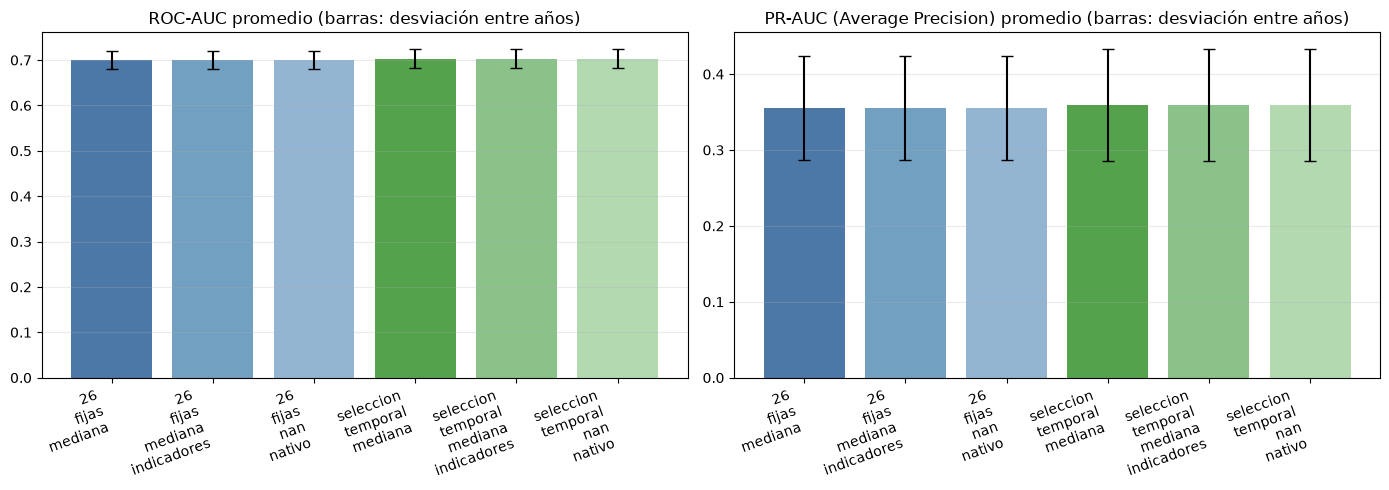

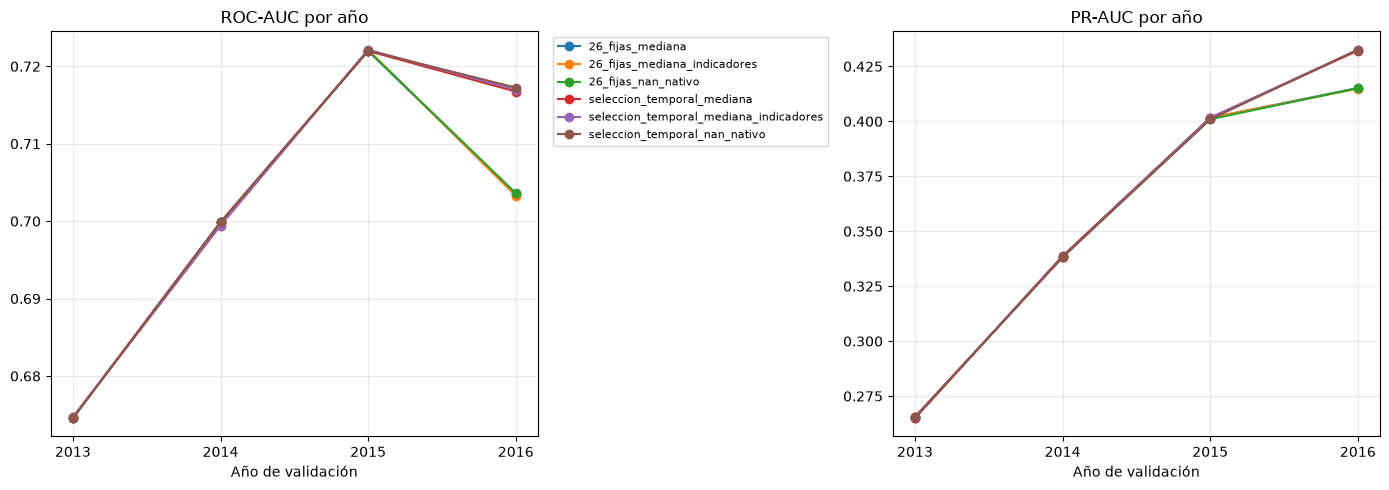

Resultados guardados en: C:\Users\josue\Proyecto-ML-Grupo8\outputs\comparacion_imputacion
26 fijas — Mediana + indicadores: delta ROC-AUC -0.00010 (2/4 cortes mejores); delta PR-AUC -0.00003 (2/4 cortes mejores).
26 fijas — NaN nativos: delta ROC-AUC +0.00003 (3/4 cortes mejores); delta PR-AUC -0.00016 (1/4 cortes mejores).
Selección temporal — Mediana + indicadores: delta ROC-AUC +0.00002 (3/4 cortes mejores); delta PR-AUC +0.00014 (3/4 cortes mejores).
Selección temporal — NaN nativos: delta ROC-AUC +0.00013 (3/4 cortes mejores); delta PR-AUC -0.00005 (2/4 cortes mejores).


In [7]:
resultados=pd.DataFrame(resultados_filas)
cobertura=pd.concat(cobertura_filas,ignore_index=True)
resumen=(resultados.groupby(["seleccion","experimento","metodo"],as_index=False)
    .agg(ROC_AUC_promedio=("ROC_AUC","mean"),ROC_AUC_desviacion=("ROC_AUC","std"),
         PR_AUC_promedio=("PR_AUC","mean"),PR_AUC_desviacion=("PR_AUC","std"),
         variables_min=("variables_originales","min"),variables_max=("variables_originales","max"),
         indicadores_promedio=("indicadores_faltantes","mean")))
resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]]=resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]].fillna(0)

filas_diferencias=[]
for conjunto,base,indicadores,nativo in [
    ("26 fijas","26_fijas_mediana","26_fijas_mediana_indicadores","26_fijas_nan_nativo"),
    ("Selección temporal","seleccion_temporal_mediana","seleccion_temporal_mediana_indicadores","seleccion_temporal_nan_nativo"),
]:
    tbase=resultados[resultados.experimento==base]
    tind=resultados[resultados.experimento==indicadores]
    tnat=resultados[resultados.experimento==nativo]
    for metodo,tabla in [("Mediana + indicadores",tind),("NaN nativos",tnat)]:
        m=tbase[["anio_validacion","ROC_AUC","PR_AUC"]].merge(
            tabla[["anio_validacion","ROC_AUC","PR_AUC"]],on="anio_validacion",suffixes=("_mediana","_comparado"))
        filas_diferencias.append({
            "conjunto":conjunto,"metodo_comparado":metodo,
            "delta_ROC_AUC_promedio":float((m.ROC_AUC_comparado-m.ROC_AUC_mediana).mean()),
            "cortes_ROC_AUC_mejor":int((m.ROC_AUC_comparado>m.ROC_AUC_mediana).sum()),
            "delta_PR_AUC_promedio":float((m.PR_AUC_comparado-m.PR_AUC_mediana).mean()),
            "cortes_PR_AUC_mejor":int((m.PR_AUC_comparado>m.PR_AUC_mediana).sum()),
        })
diferencias=pd.DataFrame(filas_diferencias)

display(resumen.round(5))
display(diferencias.round(5))
display(resultados[["experimento","anio_validacion","variables_originales","indicadores_faltantes","faltantes_numericos_entrenamiento","NaN_entrenamiento_conservados","ROC_AUC","PR_AUC"]].sort_values(["experimento","anio_validacion"]).round(5))

# Resumen de faltantes: por conjunto y año, número de variables y máximo porcentaje observado.
cobertura_resumen=(cobertura.groupby(["experimento","anio_validacion"],as_index=False)
    .agg(variables=("variable","count"),variables_con_faltantes=("faltante_pct_entrenamiento",lambda x:int((x>0).sum())),
         faltante_promedio_pct=("faltante_pct_entrenamiento","mean"),faltante_maximo_pct=("faltante_pct_entrenamiento","max"),
         indicadores=("indicador_creado","sum")))
display(cobertura_resumen.round(2))

# Gráficos de promedios y comportamiento por año.
orden=["26_fijas_mediana","26_fijas_mediana_indicadores","26_fijas_nan_nativo",
       "seleccion_temporal_mediana","seleccion_temporal_mediana_indicadores","seleccion_temporal_nan_nativo"]
resplot=resumen.set_index("experimento").reindex(orden)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,metrica,desv,titulo in [
    (axes[0],"ROC_AUC_promedio","ROC_AUC_desviacion","ROC-AUC promedio"),
    (axes[1],"PR_AUC_promedio","PR_AUC_desviacion","PR-AUC (Average Precision) promedio")]:
    ax.bar(range(len(orden)),resplot[metrica],yerr=resplot[desv],capsize=4,
           color=["#4C78A8","#72A0C1","#93B5D1","#54A24B","#8BC28A","#B2D9B0"])
    ax.set_xticks(range(len(orden)),[x.replace("_","\n") for x in orden],rotation=20,ha="right")
    ax.set_title(titulo+" (barras: desviación entre años)")
    ax.grid(axis="y",alpha=.25)
fig.tight_layout(); display(fig); plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(14,5))
for experimento in orden:
    sub=resultados[resultados.experimento==experimento].sort_values("anio_validacion")
    axes[0].plot(sub.anio_validacion,sub.ROC_AUC,marker="o",label=experimento)
    axes[1].plot(sub.anio_validacion,sub.PR_AUC,marker="o",label=experimento)
axes[0].set_title("ROC-AUC por año"); axes[1].set_title("PR-AUC por año")
for ax in axes:
    ax.set_xticks(ANIOS_VALIDACION); ax.set_xlabel("Año de validación"); ax.grid(alpha=.25)
axes[0].legend(fontsize=8,bbox_to_anchor=(1.02,1),loc="upper left")
fig.tight_layout(); display(fig); plt.close(fig)

salida=RAIZ/"outputs"/"comparacion_imputacion"
salida.mkdir(parents=True,exist_ok=True)
resultados.to_csv(salida/"metricas_por_experimento_y_anio.csv",index=False)
resumen.to_csv(salida/"resumen_promedios_y_variabilidad.csv",index=False)
diferencias.to_csv(salida/"diferencias_frente_mediana.csv",index=False)
cobertura.to_csv(salida/"faltantes_variables_por_corte.csv",index=False)
cobertura_resumen.to_csv(salida/"resumen_faltantes_por_corte.csv",index=False)
pd.DataFrame({"variable_26":pd.Series(variables_26),"candidatas":pd.Series(candidatas)}).to_csv(salida/"listas_variables.csv",index=False)
print("Resultados guardados en:",salida)
for _,r in diferencias.iterrows():
    print(f"{r['conjunto']} — {r['metodo_comparado']}: delta ROC-AUC {r['delta_ROC_AUC_promedio']:+.5f} ({int(r['cortes_ROC_AUC_mejor'])}/4 cortes mejores); delta PR-AUC {r['delta_PR_AUC_promedio']:+.5f} ({int(r['cortes_PR_AUC_mejor'])}/4 cortes mejores).")


## 4. Conclusiones

1. **El manejo nativo de NaN no mejora claramente el rendimiento general.** Con 26 variables, frente a mediana, su ROC-AUC promedio sube apenas 0.00003, mientras que PR-AUC baja 0.00016. Con selección temporal, ROC-AUC sube 0.00013 y PR-AUC baja 0.00005. Son diferencias pequeñas y hay un intercambio entre métricas.
2. **La ventaja no es consistente en ambas métricas.** NaN nativo obtuvo mayor ROC-AUC en 3 de los 4 años en ambos conjuntos. En cambio, su PR-AUC fue mayor solo en 1 de 4 años para las 26 variables y en 2 de 4 con selección temporal.
3. **El patrón es parecido con los dos conjuntos.** NaN nativo da una diferencia minúscula positiva en ROC-AUC y negativa en PR-AUC, tanto con 26 como con selección temporal; no hay evidencia de una ventaja importante que dependa del tamaño del conjunto.
4. **Los indicadores tampoco aportan una mejora clara.** Sus diferencias promedio respecto a mediana sola están muy cerca de cero: con 26 variables, −0.00010 ROC-AUC y −0.00003 PR-AUC; con selección temporal, +0.00002 y +0.00014, respectivamente.
5. **Recomendación provisional:** conservar mediana sin indicadores como opción sencilla y comparable. NaN nativo queda como candidato para una prueba posterior porque conserva un ROC-AUC casi igual y es ligeramente mayor en promedio, pero no lo declaramos superior porque PR-AUC no mejora de forma consistente. No se cambia el modelo definitivo.

La selección temporal con mediana obtiene 0.7033 ROC-AUC y 0.3593 PR-AUC, frente a 0.7000 y 0.3551 con las 26 fijas. Esa diferencia corresponde al conjunto de variables: en los cortes de 2013–2015 conserva 26, y para validar 2016 selecciona 57. No debe atribuirse al método de imputación.

Las transformaciones, medianas, indicadores y selección por corte se ajustaron con entrenamiento únicamente. El control confirma que el método nativo pasó sin alteración 945, 1,023, 1,138 y 1,294 NaN numéricos en entrenamiento para los cortes fijos; los NaN de validación también se conservaron. Los datos desde 2017 no se usaron.

## Referencias

scikit-learn developers. (s. f.). *HistGradientBoostingClassifier*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html

scikit-learn developers. (s. f.). *StandardScaler*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scikit-learn developers. (s. f.). *SimpleImputer*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html